# Tutorial 7 — Sudden shifts in collective opinion

Notebook of the programming section of chapter 7 of R. Kühn, P. Vivo and F. Zamponi,
*Introduction to statistical physics for non-physicists* (Oxford University Press).

**How to run it.** Run all cells from top to bottom, locally (Jupyter) or on Google Colab:
[open it in Colab](https://colab.research.google.com/github/francescozamponi/statphys-tutorials/blob/main/Tutorial_7/Tutorial_7.ipynb).
No data files are needed.

The random number generator is seeded, so that the notebook reproduces the figures of the book.

In [2]:
import logging
logging.getLogger('fontTools').setLevel(logging.ERROR)

import numpy as np
import math
import matplotlib.pyplot as plt
import sys, urllib.request
%matplotlib inline

BOOK_REPO = 'https://raw.githubusercontent.com/francescozamponi/statphys-tutorials/main/'

# Book formatting: every figure is saved at its printed size, so that all text prints at the
# same size in the book (bookfig.py; it does not change the plots). Without bookfig.py the
# figures are saved as they are.
sys.path[:0] = ['..', '../Figs_generator']
try:
    from bookfig import setup, save, HALF, SINGLE, FULL
except ImportError:                         # e.g. on Colab: fetch bookfig.py from the book repository
    try:
        urllib.request.urlretrieve(BOOK_REPO + 'bookfig.py', 'bookfig.py')
        from bookfig import setup, save, HALF, SINGLE, FULL
    except Exception:
        setup = None
if setup:
    setup()
else:
    HALF, SINGLE, FULL = 0.49, 0.7, 1.0
    def save(path, width, **kw):
        plt.savefig(path, bbox_inches='tight')

np.random.seed(0)   # fixed seed: reproduces the run shown in the book (sometimes the seed is changed below)

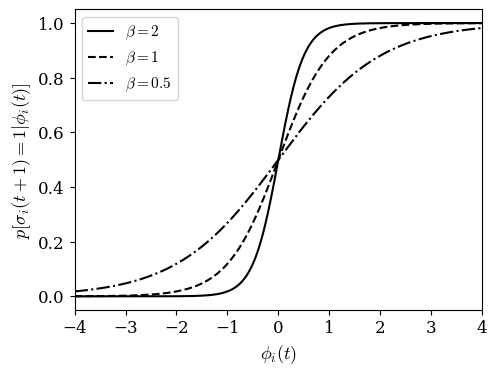

In [3]:
# SIGMOID

dist=np.zeros((1000,4));
x=-4
for i in range(0,1000):
    dist[i,0]=x
    beta=0.5
    dist[i,1]=1/(1+np.exp(-2*beta*x))
    beta=1
    dist[i,2]=1/(1+np.exp(-2*beta*x))
    beta=2
    dist[i,3]=1/(1+np.exp(-2*beta*x))
    x=x+0.01

plt.plot(dist[:,0],dist[:,3],color='black',label=r'$\beta=2$')
plt.plot(dist[:,0],dist[:,2],color='black',linestyle="--",label=r'$\beta=1$')
plt.plot(dist[:,0],dist[:,1],color='black',linestyle="-.",label=r'$\beta=0.5$')
plt.legend()
plt.xlabel(r'$\phi_i(t)$')
plt.ylabel(r'$p[\sigma_i(t+1)=1 | \phi_i(t) ]$')
plt.ylim(-0.05,1.05)
plt.xlim(-4,4)
plt.tight_layout()
save('pbeta.pdf', SINGLE)
plt.show()


## Fully connected graph, $N\to\infty$, $\beta=0.8$

In [5]:
# Use sw=1 (default) to get the fixed point aligned to h. Use sw=-1 to get the one anti-aligned to h.
def mstar(h,beta,J,init=1):
   m=init
   mnew=0
   conv=np.fabs(mnew-m)
   while conv>1e-6 :
      mnew=np.tanh(beta*(h+J*m))
      conv=np.fabs(mnew-m)
      m=mnew
   return m

In [6]:
beta=0.8
h=-0.2
J=1
H0=0.
dH=0.0001
mt=[]
Ht=[]
mt.append(-1)
Ht.append(H0)
for i in range(5000):
  mt.append(np.tanh(beta*(h+Ht[-1]+J*mt[-1])))
  Ht.append(Ht[-1]+dH)

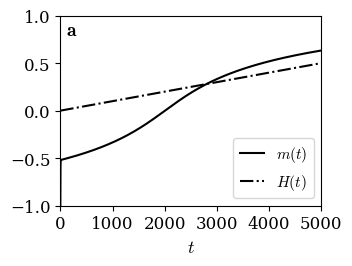

In [7]:
plt.plot(np.array(mt),label='$m(t)$',color='black')
plt.plot(np.array(Ht),label='$H(t)$',color='black',linestyle='-.')
plt.xlabel('$t$')
plt.legend(loc='lower right')
plt.text(100, 0.8, r'${\bf a}$', fontsize=36)
plt.xlim((0,5000))
plt.ylim((-1,1))
plt.tight_layout()
save(str(beta)+'_time.pdf', HALF)
plt.show()

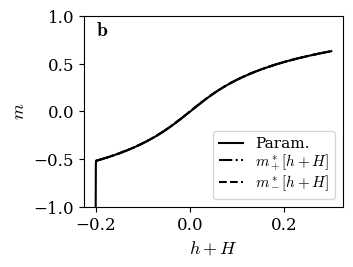

In [8]:
plt.plot(h+np.array(Ht),np.array(mt),label='Param.',color='black')
plt.plot(h+np.array(Ht),[mstar(h+x,beta,J,init=1) for x in Ht],label='$m_+^*[h+H]$',color='black',linestyle='-.')
plt.plot(h+np.array(Ht),[mstar(h+x,beta,J,init=-1) for x in Ht],label='$m_-^*[h+H]$',color='black',linestyle='--')
plt.xlabel('$h+H$')
plt.ylabel('$m$')
plt.ylim((-1,1))
plt.legend(loc='lower right', labelspacing=0.05)
plt.text(-0.2, 0.8, r'${\bf b}$', fontsize=36)
plt.tight_layout()
save(str(beta)+'_param.pdf', HALF)
plt.show()

## Fully connected graph, finite $N$

In [10]:
def finiteN(N,Tmax):
  mt=[]
  Ht=[]
  Ht.append(H0)
  S=-np.ones(N)
  mt.append(np.mean(S))
  for i in range(Tmax):
    pp=np.exp(beta*(h+Ht[-1]+J*np.mean(S)))/2/np.cosh(beta*(h+Ht[-1]+J*np.mean(S)))
    S=np.random.choice([-1,1], N, p=[1-pp,pp])
    Ht.append(Ht[-1]+dH)
    mt.append(np.mean(S))
  return mt,Ht

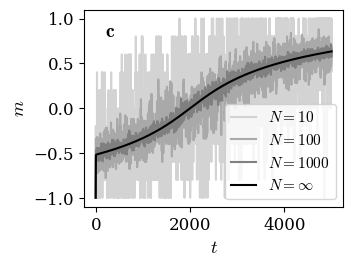

In [11]:
plt.plot(np.array(finiteN(10,5000)[0]),label=r'$N=10$',color='lightgrey')
plt.plot(np.array(finiteN(100,5000)[0]),label=r'$N=100$',color='darkgrey')
plt.plot(np.array(finiteN(1000,5000)[0]),label=r'$N=1000$',color='grey')
plt.plot(np.array(mt),label=r'$N=\infty$',color='black')
plt.xlabel(r'$t$')
plt.ylabel(r'$m$')
plt.text(200, 0.8, r'${\bf c}$', fontsize=36)
plt.legend(loc='lower right')
plt.tight_layout()
save(str(beta)+'_timeN.pdf', HALF)
plt.show()

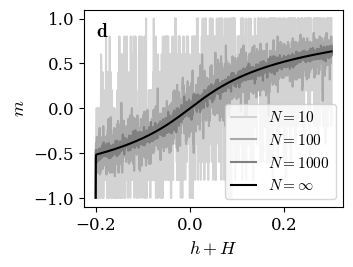

In [12]:
plt.plot(h+np.array(Ht),np.array(finiteN(10,5000)[0]),label=r'$N=10$',color='lightgrey')
plt.plot(h+np.array(Ht),np.array(finiteN(100,5000)[0]),label=r'$N=100$',color='darkgrey')
plt.plot(h+np.array(Ht),np.array(finiteN(1000,5000)[0]),label=r'$N=1000$',color='grey')
plt.plot(h+np.array(Ht),np.array(mt),label=r'$N=\infty$',color='black')
plt.xlabel(r'$h+H$')
plt.ylabel(r'$m$')
plt.text(-0.2, 0.8, r'${\bf d}$', fontsize=36)
plt.legend(loc='lower right')
plt.tight_layout()
save(str(beta)+'_paramN.pdf', HALF)
plt.show()

## Same analysis with $\beta=1.1$

In [14]:
beta=1.1
h=-0.2
J=1
H0=0.
dH=0.0001
mt=[]
Ht=[]
mt.append(-1)
Ht.append(H0)
for i in range(5000):
  mt.append(np.tanh(beta*(h+Ht[-1]+J*mt[-1])))
  Ht.append(Ht[-1]+dH)

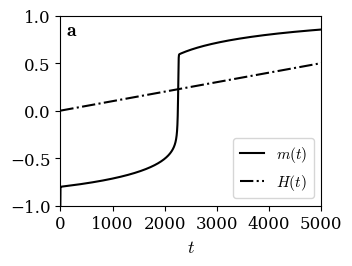

In [15]:
plt.plot(np.array(mt),label='$m(t)$',color='black')
plt.plot(np.array(Ht),label='$H(t)$',color='black',linestyle='-.')
plt.xlabel('$t$')
plt.legend(loc='lower right')
plt.text(100, 0.8, r'${\bf a}$', fontsize=36)
plt.xlim((0,5000))
plt.ylim((-1,1))
plt.tight_layout()
save(str(beta)+'_time.pdf', HALF)
plt.show()

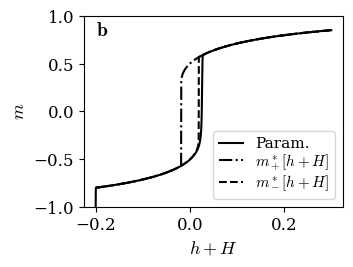

In [16]:
plt.plot(h+np.array(Ht),np.array(mt),label=r'Param.',color='black')
plt.plot(h+np.array(Ht),[mstar(h+x,beta,J,init=1) for x in Ht],label=r'$m_+^*[h+H]$',color='black',linestyle='-.')
plt.plot(h+np.array(Ht),[mstar(h+x,beta,J,init=-1) for x in Ht],label=r'$m_-^*[h+H]$',color='black',linestyle='--')
plt.xlabel(r'$h+H$')
plt.ylabel(r'$m$')
plt.ylim((-1,1))
plt.legend(loc='lower right', labelspacing=0.05)
plt.text(-0.2, 0.8, r'${\bf b}$', fontsize=36)
plt.tight_layout()
save(str(beta)+'_param.pdf', HALF)
plt.show()

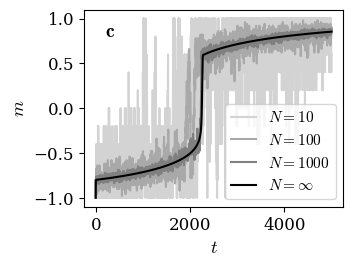

In [17]:
plt.plot(np.array(finiteN(10,5000)[0]),label=r'$N=10$',color='lightgrey')
plt.plot(np.array(finiteN(100,5000)[0]),label=r'$N=100$',color='darkgrey')
plt.plot(np.array(finiteN(1000,5000)[0]),label=r'$N=1000$',color='grey')
plt.plot(np.array(mt),label=r'$N=\infty$',color='black')
plt.xlabel(r'$t$')
plt.ylabel(r'$m$')
plt.text(200, 0.8, r'${\bf c}$', fontsize=36)
plt.legend(loc='lower right')
plt.tight_layout()
save(str(beta)+'_timeN.pdf', HALF)
plt.show()

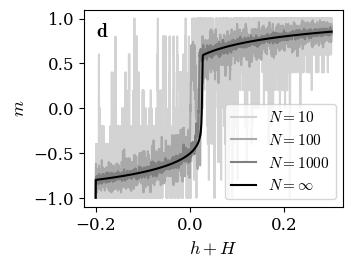

In [18]:
plt.plot(h+np.array(Ht),np.array(finiteN(10,5000)[0]),label=r'$N=10$',color='lightgrey')
plt.plot(h+np.array(Ht),np.array(finiteN(100,5000)[0]),label=r'$N=100$',color='darkgrey')
plt.plot(h+np.array(Ht),np.array(finiteN(1000,5000)[0]),label=r'$N=1000$',color='grey')
plt.plot(h+np.array(Ht),np.array(mt),label=r'$N=\infty$',color='black')
#plt.plot(h+np.array(Ht),[mstar(h+x,beta,J) for x in Ht])
plt.xlabel(r'$h+H$')
plt.ylabel(r'$m$')
plt.text(-0.2, 0.8, r'${\bf d}$', fontsize=36)
plt.legend(loc='lower right')
plt.tight_layout()
save(str(beta)+'_paramN.pdf', HALF)
plt.show()

### A long run at fixed field (not shown in the book)

$\beta=1.1$, $N=1000$, with the external field kept fixed at $H=0.21$ for $10^5$ steps.

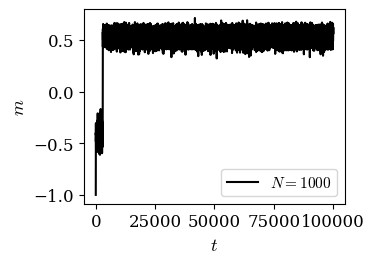

In [20]:
beta=1.1
h=-0.2
J=1
H0=0.21
dH=0.0
plt.plot(np.array(finiteN(1000,100000)[0]),label='$N=1000$',color='black')
plt.xlabel('$t$')
plt.ylabel('$m$')
plt.legend(loc='lower right')
plt.show()

## Fully connected graph, $N\to\infty$, heterogeneous agents

In [22]:
def mstar(h,sigmah,J,init=1):
   m=init
   mnew=0
   conv=np.fabs(mnew-m)
   while conv>1e-6 :
      mnew=math.erf((h+J*m)/np.sqrt(2)/sigmah)
      conv=np.fabs(mnew-m)
      m=mnew
   return m

In [23]:
sigmah=0.9/np.sqrt(2)
muh=-0.2
J=1
H0=0.
dH=0.0001
mt=[]
Ht=[]
mt.append(-1)
Ht.append(H0)
for i in range(10000):
  mt.append(math.erf((muh+Ht[-1]+J*mt[-1])/np.sqrt(2)/sigmah))
  Ht.append(Ht[-1]+dH)

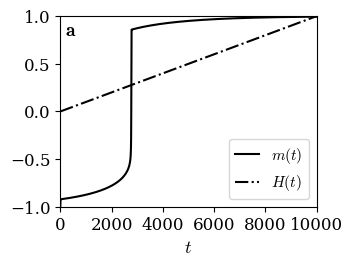

In [24]:
plt.plot(np.array(mt),label=r'$m(t)$',color='black')
plt.plot(np.array(Ht),label=r'$H(t)$',color='black',linestyle='-.')
plt.xlabel(r'$t$')
plt.legend(loc='lower right')
plt.text(200, 0.8, r'${\bf a}$', fontsize=36)
plt.xlim((0,10000))
plt.ylim((-1,1))
plt.tight_layout()
save('sigma_time.pdf', HALF)
plt.show()

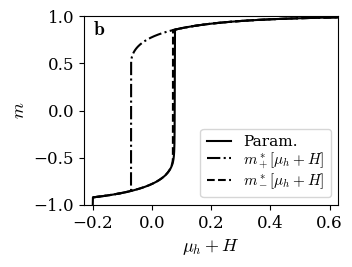

In [25]:
plt.plot(muh+np.array(Ht),np.array(mt),label=r'Param.',color='black')
plt.plot(muh+np.array(Ht),[mstar(muh+x,sigmah,J,init=1) for x in Ht],label=r'$m_+^*[\mu_h+H]$',color='black',linestyle='-.')
plt.plot(muh+np.array(Ht),[mstar(muh+x,sigmah,J,init=-1) for x in Ht],label=r'$m_-^*[\mu_h+H]$',color='black',linestyle='--')
plt.xlabel(r'$\mu_h+H$')
plt.ylabel(r'$m$')
plt.xlim((-0.23,0.63))
plt.ylim((-1,1))
plt.legend(loc='lower right', labelspacing=0.05)
plt.text(-0.2, 0.8, r'${\bf b}$', fontsize=36)
plt.tight_layout()
save('sigma_param.pdf', HALF)
plt.show()

## Fully connected graph, finite $N$, heterogeneous agents

In [27]:
def finiteN(N):
  mt=[]
  Ht=[]
  Ht.append(H0)
  S=-np.ones(N)
  h=np.random.normal(muh,sigmah,N)
  mt.append(np.mean(S))
  for i in range(10000):
    S=np.sign(h+Ht[-1]+J*np.mean(S))
    Ht.append(Ht[-1]+dH)
    mt.append(np.mean(S))
  return mt,Ht

In [28]:
np.random.seed(60)  # chosen for nicer visualization
m10=np.array(finiteN(10)[0])
m100=np.array(finiteN(100)[0])
m1000=np.array(finiteN(1000)[0])

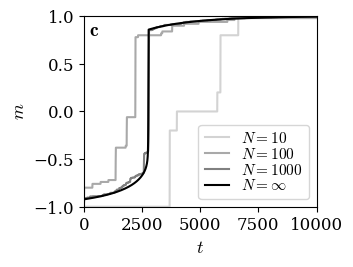

In [29]:
plt.plot(m10,label=r'$N=10$',color='lightgrey')
plt.plot(m100,label=r'$N=100$',color='darkgrey')
plt.plot(m1000,label=r'$N=1000$',color='grey')
plt.plot(np.array(mt),label=r'$N=\infty$',color='black')
plt.text(200, 0.8, r'${\bf c}$', fontsize=36)
plt.xlabel(r'$t$')
plt.ylabel(r'$m$')
plt.xlim((0,10000))
plt.ylim((-1,1))
plt.legend(loc='lower right', labelspacing=0.05)
plt.tight_layout()
save('sigma_timeN.pdf', HALF)
plt.show()

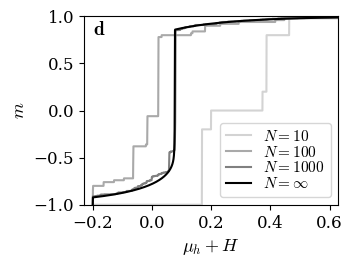

In [30]:
plt.plot(muh+np.array(Ht),m10,label=r'$N=10$',color='lightgrey')
plt.plot(muh+np.array(Ht),m100,label=r'$N=100$',color='darkgrey')
plt.plot(muh+np.array(Ht),m1000,label=r'$N=1000$',color='grey')
plt.plot(muh+np.array(Ht),np.array(mt),label=r'$N=\infty$',color='black')
plt.xlabel(r'$\mu_h+H$')
plt.ylabel(r'$m$')
plt.text(-0.2, 0.8, r'${\bf d}$', fontsize=36)
plt.xlim((-0.23,0.63))
plt.ylim((-1,1))
plt.legend(loc='lower right', labelspacing=0.05)
plt.tight_layout()
save('sigma_paramN.pdf', HALF)
plt.show()